# Lab Assignment 2

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import HDBSCAN
from sklearn.datasets import load_iris
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

In [2]:
iris = load_iris()
X = iris.data
y = iris.target
feature_names = iris.feature_names
target_names = iris.target_names

In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [4]:
hdb = HDBSCAN(min_cluster_size=5)
labels = hdb.fit_predict(X_scaled)

d:\anaconda3\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


In [8]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
df_eval = pd.DataFrame({
    'PC1': X_pca[:, 0],
    'PC2': X_pca[:, 1],
    'True_Label': [target_names[i] for i in y],
    'HDBSCAN_Label': labels,
})

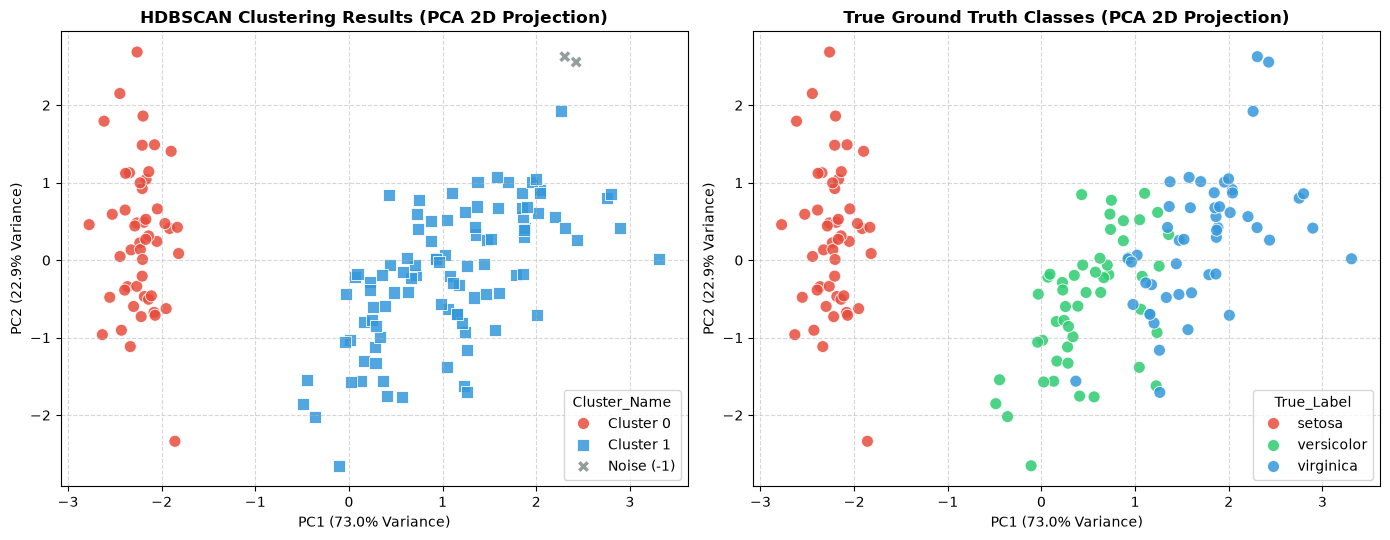

In [ ]:
df_eval['Cluster_Name'] = df_eval['HDBSCAN_Label'].map(
    {-1: 'Noise (-1)', 0: 'Cluster 0', 1: 'Cluster 1'}
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Subplot 1: HDBSCAN Clustering Outp ut
palette_hdb = {
    'Noise (-1)': '#7f8c8d',
    'Cluster 0': '#e74c3c',
    'Cluster 1': '#3498db',
}
sns.scatterplot(
    data=df_eval,
    x='PC1',
    y='PC2',
    hue='Cluster_Name',
    palette=palette_hdb,
    style='Cluster_Name',
    markers={'Noise (-1)': 'X', 'Cluster 0': 'o', 'Cluster 1': 's'},
    s=75,
    alpha=0.85,
    ax=axes[0],
)
axes[0].set_title(
    'HDBSCAN Clustering Results (PCA 2D Projection)',
    fontsize=12,
    fontweight='bold',
)
axes[0].set_xlabel(
    f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% Variance)', fontsize=10
)
axes[0].set_ylabel(
    f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% Variance)', fontsize=10
)
axes[0].grid(True, linestyle='--', alpha=0.5)

# Subplot 2: Ground Truth Species
palette_true = {
    'setosa': '#e74c3c',
    'versicolor': '#2ecc71',
    'virginica': '#3498db',
}
sns.scatterplot(
    data=df_eval,
    x='PC1',
    y='PC2',
    hue='True_Label',
    palette=palette_true,
    s=75,
    alpha=0.85,
    ax=axes[1],
)
axes[1].set_title(
    'True Ground Truth Classes (PCA 2D Projection)',
    fontsize=12,
    fontweight='bold',
)
axes[1].set_xlabel(
    f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% Variance)', fontsize=10
)
axes[1].set_ylabel(
    f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% Variance)', fontsize=10
)
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

The HDBSCAN clustering results partially correspond to the dataset's original labels. Iris-setosa is separated from the other species by a wide low-density margin. HDBSCAN groups it into Cluster 0 with nearly 100% precision.Unlike parametric algorithms that enforce a fixed $k=3$ partition regardless of density, HDBSCAN is a non-parametric density-based algorithm. Because Iris-versicolor and Iris-virginica morphologically transition into each other without a low-density "valley" or separation gap between them, HDBSCAN views them as a single continuous high-density component, grouping both into Cluster 1 (98–100 samples).